In [7]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

data = pd.read_csv("data_grupp_13.csv")

X = data.drop(columns=["target"])
y = data["target"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(data.head())


   besok_per_manad  snittorder_kr  tid_pa_sajt_sek  returgrad  \
0             11.9         1690.0            261.0       0.36   
1             16.5         2993.0            770.0       0.10   
2             17.7          536.0            102.0       0.00   
3             10.4         1834.0            355.0       0.04   
4              5.2          942.0            165.0       0.54   

   kundtjanst_arenden  rabattkod_andel          target  
0                 5.3             0.24  Risk_for_churn  
1                 0.0             0.36  Lojal_stamkund  
2                 1.4             0.85      Fyndjagare  
3                 0.2             0.26  Lojal_stamkund  
4                 2.6             0.42  Risk_for_churn  


In [8]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_base = RandomForestClassifier(random_state=42)

scores = cross_validate(
    rf_base,
    X_scaled,
    y,
    cv=cv5,
    scoring={"acc": "accuracy", "f1_macro": "f1_macro"},
)

print(f"Accuracy:  {scores['test_acc'].mean():.4f} +/- {scores['test_acc'].std():.4f}")
print(f"F1 macro:  {scores['test_f1_macro'].mean():.4f} +/- {scores['test_f1_macro'].std():.4f}")

Accuracy:  0.9958 +/- 0.0083
F1 macro:  0.9958 +/- 0.0083


Matplotlib is building the font cache; this may take a moment.


 param_n_estimators  param_max_depth  mean_test_score  std_test_score  rank_test_score
                100                2         0.995829        0.008341                1
                200                2         0.995829        0.008341                1
                100                3         0.995829        0.008341                1
                200                6         0.995829        0.008341                1
                 50                6         0.995829        0.008341                1
                100                6         0.995829        0.008341                1
                200                3         0.995829        0.008341                1
                 50                2         0.991659        0.010216                8
                 50                3         0.991659        0.010216                8
                 50                1         0.987488        0.010216               10
                 10                6       

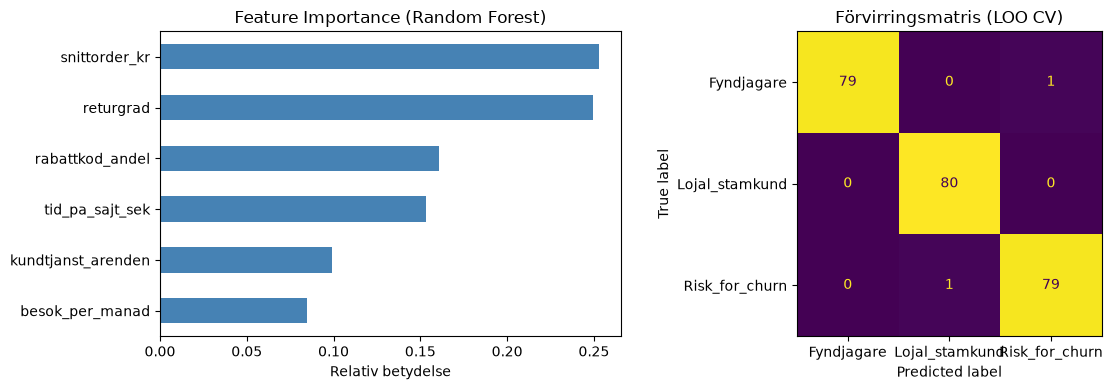


Felklassificerade observationer:
     besok_per_manad  snittorder_kr  tid_pa_sajt_sek  returgrad  \
49              11.2         1736.0            254.0       0.18   
221             17.4           80.0            245.0       0.34   

     kundtjanst_arenden  rabattkod_andel          target      prediktion  
49                  5.6             0.42  Risk_for_churn  Lojal_stamkund  
221                 1.2             0.63      Fyndjagare  Risk_for_churn  


In [10]:
import time
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, LeaveOneOut, StratifiedKFold, cross_val_predict, cross_validate

n_folds = 5  # Kontrollera mot Grupp 13 i tilldelning_canvas.csv
cv_assigned = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

param_grid = {
    "n_estimators": [10, 50, 100, 200],
    "max_depth": [1, 2, 3, 6],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=cv_assigned,
    scoring="f1_macro",
    n_jobs=-1,
)
grid.fit(X_scaled, y)

results_df = pd.DataFrame(grid.cv_results_)[
    ["param_n_estimators", "param_max_depth", "mean_test_score", "std_test_score", "rank_test_score"]
]
print(results_df.sort_values("rank_test_score").to_string(index=False))
print("\nBästa parametrar:", grid.best_params_)

best_rf = RandomForestClassifier(**grid.best_params_, random_state=42)

t0 = time.perf_counter()
cv_res = cross_validate(
    best_rf, X_scaled, y, cv=cv_assigned, scoring={"acc": "accuracy", "f1_macro": "f1_macro"}
)
time_cv = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_loo = cross_val_predict(best_rf, X_scaled, y, cv=LeaveOneOut())
time_loo = time.perf_counter() - t0

print(f"\n{n_folds}-fold Stratified CV -> Acc: {cv_res['test_acc'].mean():.4f} (+/- {cv_res['test_acc'].std():.4f}), F1 macro: {cv_res['test_f1_macro'].mean():.4f}, Tid: {time_cv:.3f}s")
print(f"LOO CV                 -> Acc: {accuracy_score(y, y_pred_loo):.4f}, F1 macro: {f1_score(y, y_pred_loo, average='macro'):.4f}, Tid: {time_loo:.3f}s")

best_rf.fit(X_scaled, y)
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
importances.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Feature Importance (Random Forest)")
axes[0].set_xlabel("Relativ betydelse")

cm = confusion_matrix(y, y_pred_loo, labels=best_rf.classes_)
ConfusionMatrixDisplay(cm, display_labels=best_rf.classes_).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Förvirringsmatris (LOO CV)")
plt.tight_layout()
plt.show()

fel_mask = y != y_pred_loo
print("\nFelklassificerade observationer:")
print(data[fel_mask].assign(prediktion=y_pred_loo[fel_mask]))